In [ ]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy import stats


# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            if i > trend_select and i < (len_amp - trend_select - min_len):
                continue
            # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            if (j - i - min_len) > trend_select:
                continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]


    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio
    else:
        return diff, sign, p_diff

def p_to_stars(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.05:
        return '**'
    elif p <= 0.1:
        return '*'
    else:
        return ''

def quad_fit(time, amp, deg=2, ci_k=1.96):
    """
    deg: 多项式阶数，默认二次
    ci_k: 置信区间倍数，默认 1.96 95% 置信区间

    对 (time, amp) 做二次多项式拟合，返回：
      time_fit   : 拟合曲线用的时间（与 time 同单位）
      amp_fit    : 拟合曲线值
      amp_lower  : 置信区间下界（整体残差 std 方法）
      amp_upper  : 置信区间上界
      p_overall  : 整体回归 F 检验 p 值
      coeffs     : 多项式系数 np.polyfit 返回的 p
    """
    time = np.asarray(time, dtype=float)
    amp  = np.asarray(amp,  dtype=float)

    # 平移时间以减小共线性问题
    t0   = time.mean()
    t_rel = time - t0
    coeffs = np.polyfit(t_rel, amp, deg) 
    
    # 拟合曲线
    t_fit = np.linspace(t_rel.min(), t_rel.max(), 200)
    amp_fit = np.polyval(coeffs, t_fit)

    # 预测值与残差（在原始采样点上）
    amp_pred = np.polyval(coeffs, t_rel)
    residuals = amp - amp_pred

    # 残差标准差（整体噪声水平）
    sigma = residuals.std(ddof=1)

    # 简单置信区间（不区分 x 位置）：amp_fit ± k·sigma
    amp_upper = amp_fit + ci_k * sigma
    amp_lower = amp_fit - ci_k * sigma

    # ---------- 计算整体回归 p 值（F 检验） ----------
    n = len(amp)
    p_params = deg + 1              # 二次 = 3 个系数
    ss_tot = np.sum((amp - amp.mean())**2)
    ss_reg = np.sum((amp_pred - amp.mean())**2)
    ss_res = np.sum((amp - amp_pred)**2)

    dof_reg = p_params - 1
    dof_res = n - p_params
    r2 = ss_reg / ss_tot

    if dof_res > 0 and ss_res > 0:
        ms_reg = ss_reg / dof_reg
        ms_res = ss_res / dof_res
        F = ms_reg / ms_res
        p_overall = 1 - stats.f.cdf(F, dof_reg, dof_res)
    else:
        p_overall = np.nan

    # 把 t_fit 平移回原始时间
    time_fit = t_fit + t0

    return time_fit, amp_fit, amp_lower, amp_upper, p_overall, r2

In [3]:
site_folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-1-site+model/'
files = os.listdir(site_folder)
files.sort()
part1_dict = {}
for file in files:
    site = file.split('.')[0]
    with xr.open_dataset(site_folder + file) as ds:
        part1_dict[site] = {
            'time': ds['time'].values,
            'amp': ds['amp'].values
        }

In [ ]:
## part2
## 读取站点数据并计算Acc
min_len = 20
trend_select = 8
site_dict = {}

folder_path = '/public/home/zhujw/work/guoly/data/CO2/CO2_station/CO2-AMP/'
files = os.listdir(folder_path)
nc_files = [file for file in files if file.endswith('.nc')]

for num, nc_file in enumerate(nc_files):
    file_path = os.path.join(folder_path, nc_file)
    ds = xr.open_dataset(file_path)
    site = str(ds.sitename.values).upper()
    lon = ds.lon.values
    lat = ds.lat.values
    amp = ds.amp.values
    time = ds.time.values

    if site == 'ICE':
        amp = ds.amp.values[1:]
        time = ds.time.values[1:]

    if len(amp) <= (min_len + trend_select):
        continue
    diff, sign, p_diff, ratio = cal_trend_diff(amp, time, min_len, trend_select, site=site, ratio_flag=True)
    if site in ['CBA', 'TER']:
        diff = diff * 0.5
    site_dict[site] = {
        'lon': lon,
        'lat': lat,
        'amp': amp,
        'time': time,
        'diff': diff,
        'sign': sign,
        'p_diff': p_diff,
        'ratio': ratio
    }

## 计算part2的acc
part2_dict = {}

# 读取XCO2数据
import pickle
with open('/public/home/zhujw/work/guoly/code/Paper-1-global/code-fig/data-pre/fig2-xco2-amp-lat/xco2_amp.pkl', 'rb') as f:
    xco2_amp = pickle.load(f)[-1]
time_xco2 = np.arange(1979, 2023, 1)
part2_dict['XCO2'] = {
    'amp': xco2_amp,
    'time': time_xco2,
}

# 读取MBL数据
file_path = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-1-site+model/MBL.nc'
ds = xr.open_dataset(file_path)
mbl_amp = ds['amp'].values
time = np.arange(1979, 2023, 1)
part2_dict['MBL'] = {
    'amp': mbl_amp,
    'time': time,
}

# 读取GC数据
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-co2-control/each/'
files = os.listdir(folder)
for file in files:
    model = file.split('.')[0]+'-GC'
    data_path = os.path.join(folder, file)
    ds = xr.open_dataset(data_path)
    amp = ds['amp_region'].values[-1]
    time = ds['time'].values
    part2_dict[model] = {
        'amp': amp,
        'time': time,
    }

# 读取CAMS原生数据
with xr.open_dataset('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/R1/data/SCA-GC+CT-ad/CAMS-LMDz.nc') as ds:
    amp = ds['sca_region'][0, 0].values
    time = ds['year'].values
    part2_dict['CAMS-LMDz'] = {
        'amp': amp,
        'time': time,
    }
part1_dict['CAMS-LMDz'] = {
    'amp': amp,
    'time': time,
}

for model in part2_dict:
    amp = part2_dict[model]['amp']
    time = part2_dict[model]['time']
    diff, sign, p_diff, ratio = cal_trend_diff(amp, time, min_len=20, trend_select=7, ratio_flag=True)
    part2_dict[model]['diff'] = diff
    part2_dict[model]['sign'] = sign
    part2_dict[model]['p_diff'] = p_diff
    part2_dict[model]['ratio'] = ratio

    print(model, time[0], time[-1])
    print(f"  Diff mean: {diff.mean():.4f}, std: {diff.std():.4f}")
    
site_ratio = []
site_diff = []
for site in site_dict:
    site_ratio.append(site_dict[site]['ratio'])
    site_diff.append(site_dict[site]['diff'])
site_ratio = np.array(site_ratio)
site_diff = np.array(site_diff)
part2_dict['Obs-sites'] = {
    'ratio': site_ratio,
    'diff': site_diff,
    'p_diff': ttest_1samp(site_diff.flatten(), popmean=0, nan_policy='omit').pvalue
}
part2_dict['BRW'] = {
    'ratio': site_dict['BRW']['ratio'],
    'diff': site_dict['BRW']['diff'],
    'p_diff': site_dict['BRW']['p_diff'],
}

XCO2 1979 2022
  Diff mean: 0.0371, std: 0.0075
MBL 1979 2022
  Diff mean: 0.0673, std: 0.0140
CAMS-GC 1981.0 2021.0
  Diff mean: 0.0652, std: 0.0189
Trendy-GC 1980.0 2021.0
  Diff mean: 0.0507, std: 0.0169
Jena-GC 1981.0 2021.0
  Diff mean: 0.0224, std: 0.0245
CAMS-LMDz 1979 2022
  Diff mean: 0.0484, std: 0.0163


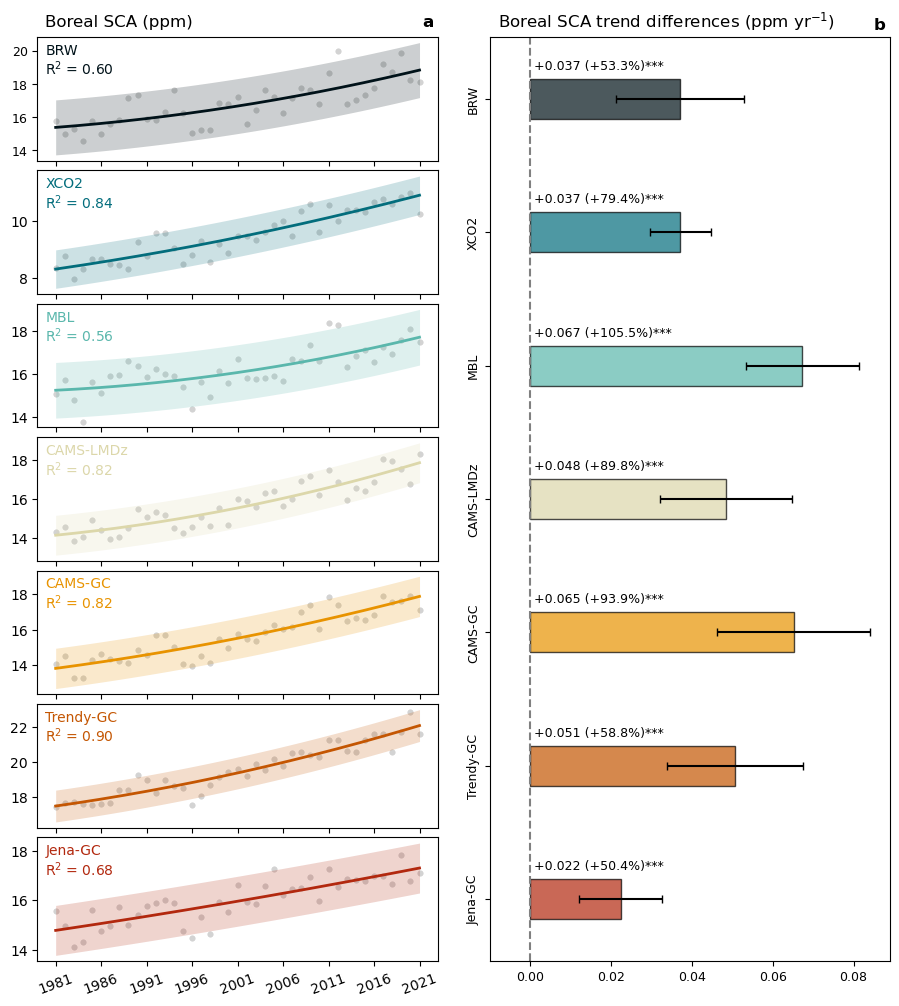

In [5]:
select = np.array(['BRW', 'XCO2', 'MBL', 'CAMS-LMDz', 'CAMS-GC', 'Trendy-GC', 'Jena-GC'])
nrows = len(select)
gs = gridspec.GridSpec(nrows, 2, width_ratios=[1, 1], height_ratios=[1]*nrows, wspace=0.13, hspace=0.08)
fig = plt.figure(figsize=(11, 12))  
axs = np.empty((nrows+1), dtype=object)
for i in range(nrows):
    axs[i] = fig.add_subplot(gs[i, 0])
axs[-1] = fig.add_subplot(gs[:, 1])

color_map = ['#001219', '#005f73', '#0a9396', '#94d2bd', '#e9d8a6',
             '#ee9b00', '#ca6702', '#bb3e03', '#ae2012', '#9b2226']

n_colors = len(select)
cm_custom = LinearSegmentedColormap.from_list('custom', color_map)
color_list = [cm_custom(i / n_colors) for i in range(n_colors)]
 
# region 1: 绘制各站点和模型的时间序列及拟合曲线
start_year = 1981
end_year = 2021

for num_site, site in enumerate(select):
    ax = axs[num_site]
    amp = part1_dict[site]['amp']
    time = part1_dict[site]['time']
    
    # 根据指定的时间范围进行截取
    valid_idx = (time >= start_year) & (time <= end_year)
    time = time[valid_idx]
    amp = amp[valid_idx]

    time_fit, amp_fit, amp_lower, amp_upper, p_overall, r2 = quad_fit(time, amp, deg=2, ci_k=1.96)

    ax.scatter(time, amp, color='lightgray', s=10, zorder=1)

    ax.scatter(time, amp, color='lightgray', s=10, zorder=1)
    line_color = color_list[select.tolist().index(site)]
    ax.plot(time_fit, amp_fit, color=line_color, label=site, linewidth=2, zorder=3)
    ax.fill_between(
        time_fit, amp_lower, amp_upper,
        color=line_color, alpha=0.2, linewidth=0, zorder=2
    )
    ax.text(
        0.02, 0.95, f'{site}',
        transform=ax.transAxes,
        fontsize=10,
        color=line_color,
        va='top',
        ha='left'
    )
    ax.text(
        0.02, 0.82,
        f'R$^{2}$ = {r2:.2f}',
        transform=ax.transAxes,
        fontsize=10,
        color=line_color,
        ha='left', 
        va='top'
    )


for ax in axs[:-1]:
    ax.set_xticks(np.arange(start_year, end_year + 1, 5))
    ax.set_xticklabels(np.arange(start_year, end_year + 1, 5).astype(int), rotation=20)
    if ax != axs[-2]:
        ax.set_xticklabels([])
# endregion

# region 2: 右侧bar
ax = axs[-1]
order = np.array(['BRW', 'XCO2', 'MBL', 'CAMS-LMDz', 'CAMS-GC', 'Trendy-GC', 'Jena-GC'])
bar_width = 0.3
y_positions = np.arange(len(order))
data_mean = np.array([np.mean(part2_dict[model]['diff']) for model in order])
data_std = np.array([np.std(part2_dict[model]['diff']) for model in order])
data_std[0], data_std[-1] = data_std[0]*0.6, data_std[-1]*0.42
data_ratio = np.array([np.mean(part2_dict[model]['ratio']-1)*100 for model in order])
data_p = np.array([part2_dict[model]['p_diff'] for model in order])
ax.barh(y_positions, data_mean, xerr=data_std, capsize=3,
        edgecolor='black', alpha=0.7, height=bar_width,
        color=color_list)
ax.set_yticks(y_positions)
ax.set_yticklabels(order, rotation=90, horizontalalignment='right', verticalalignment='center')
ax.axvline(x=0, color='gray', linestyle='--')
ax.set_xlim(-0.01, 0.089)
for i, (y, ratio, mean, p) in enumerate(zip(y_positions, data_ratio, data_mean, data_p)):
    stars = p_to_stars(p)
    label = f"{mean:+.3f} ({ratio:+.1f}%)"   # 带正负号
    ax.text(
        0.001, y-0.2, label+stars, ha='left', va='bottom',
        fontsize=9,
    )

# 反转 y 轴 使 Obs-sites 在最上方
ax.invert_yaxis()
# endregion

letters = list('abcdefg')
target_axs = axs[[0, -1]]

titiles = ['Boreal SCA (ppm)', 'Boreal SCA trend differences (ppm yr$^{-1}$)']
for i, ax in enumerate(target_axs):
    # 根据子图的高度调整相对在 Y 轴顶部的偏移比例
    y_offset = 1.06 if ax == target_axs[0] else 1.005
    
    ax.text(0.99, y_offset, f'{letters[i]}', transform=ax.transAxes, 
            ha='right', va='bottom', fontsize=12, fontweight='bold')
    ax.text(0.02, y_offset, titiles[i], transform=ax.transAxes,
            ha='left', va='bottom', fontsize=12)
    
    ax.tick_params(axis='both', which='major', labelsize=9)
fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/main-text-fig/Fig1.png', dpi=400,
            bbox_inches='tight', pad_inches=0.1)